In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dataclasses import dataclass

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import ElasticNet
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_squared_log_error
)

Dataset shape: (1460, 81)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-nu

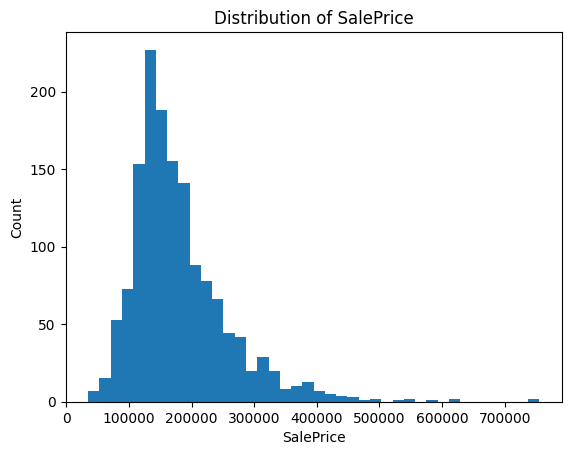

In [6]:
df = pd.read_csv("../data/train.csv") #House Prices - Advanced Regression Techniques downloaded data and use train dataset

#there is file data desription that have info about dataset and colums and their explanations 
# Basic info as shape
print("Dataset shape:", df.shape)

# First rows: understand what a "house" looks like
df.head()

 #   We first inspected the dataset using head() to understand the structure and types of variables
df.info()
# from info we can see which columns are numerical (int64, float64) and categorical (object)

print("Target summary:") #we need to understand our target obviously
df["SalePrice"].describe()
plt.figure()
plt.hist(df["SalePrice"], bins=40)
plt.title("Distribution of SalePrice")
plt.xlabel("SalePrice")
plt.ylabel("Count")
plt.show()
#The target variable SalePrice is right-skewed, indicating a small number of very expensive houses

In [7]:
#next we need to understand which features we actually can use to predict our target so we look at correlation with numerical features 

# Select numeric columns only
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns

# Correlation with target
corr_with_target = (
    df[numeric_cols]
    .corr()["SalePrice"]
    .sort_values(ascending=False)
)

corr_with_target.head(15)
#Correlation does not imply causation, but provides a useful first indication of potentially informative predictors

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
GarageYrBlt     0.486362
MasVnrArea      0.477493
Fireplaces      0.466929
BsmtFinSF1      0.386420
Name: SalePrice, dtype: float64

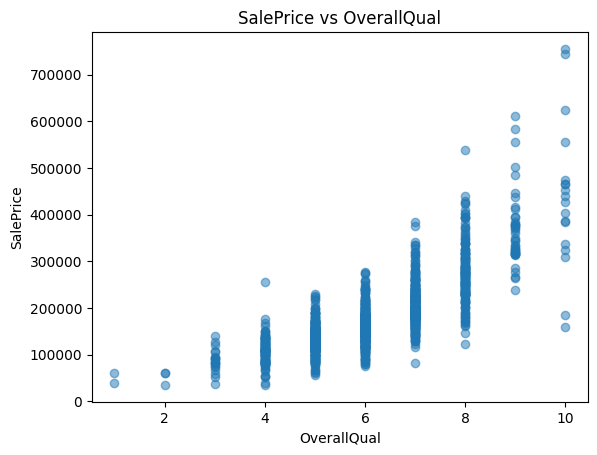

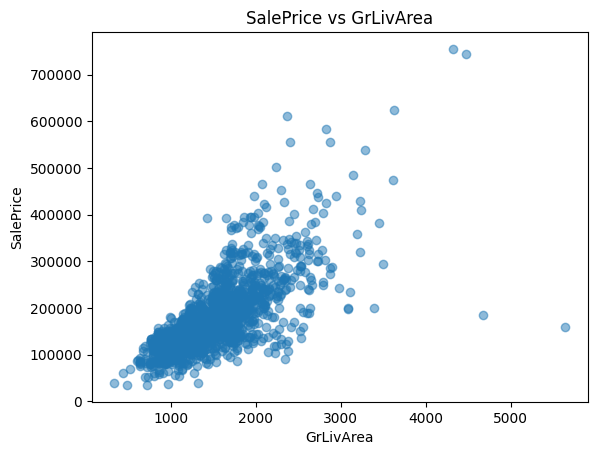

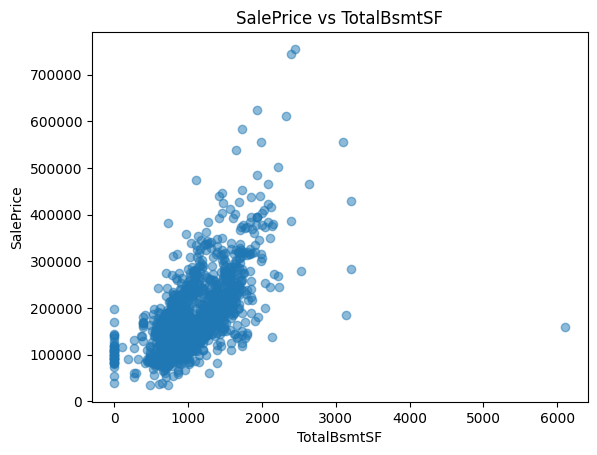

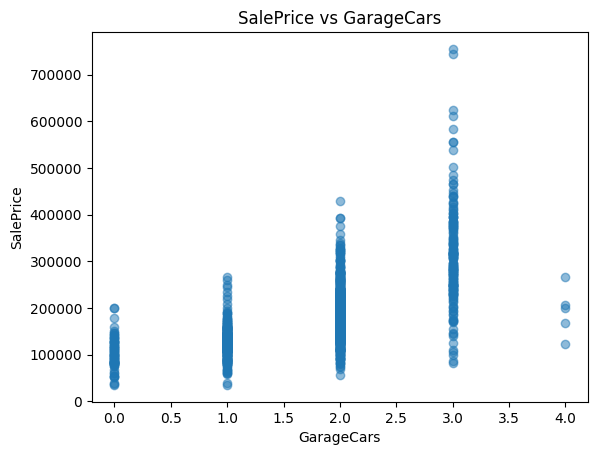

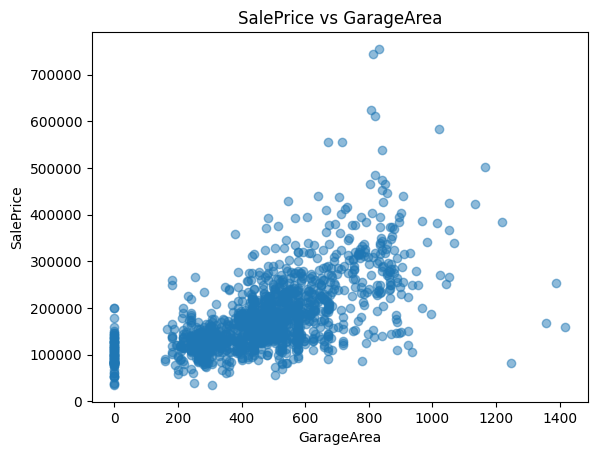

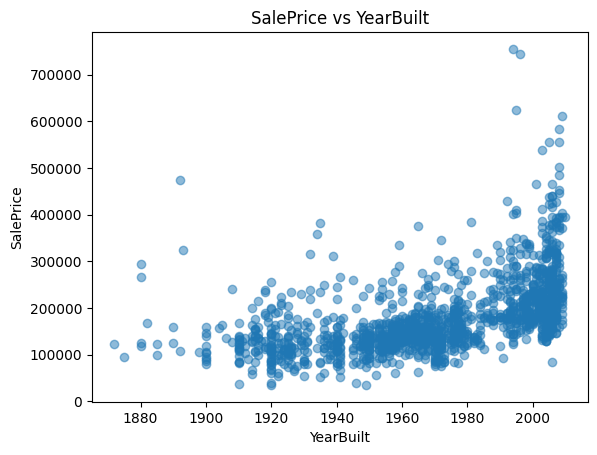

In [8]:
key_numeric = [
    "OverallQual",
    "GrLivArea",
    "TotalBsmtSF",
    "GarageCars",
    "GarageArea",
    "YearBuilt"
]

for col in key_numeric:
    plt.figure()
    plt.scatter(df[col], df["SalePrice"], alpha=0.5)
    plt.xlabel(col)
    plt.ylabel("SalePrice")
    plt.title(f"SalePrice vs {col}")
    plt.show()



The target variable SalePrice is strongly right-skewed, with most houses clustered between 100k and 250k and a small number of very expensive outliers. This suggests that prediction errors may be larger for high-price houses and motivates the use of metrics such as RMSLE (regression metric measuring the ratio-based difference between predicted and actual values)

OverallQual/GarageCars - clear vertical stripes that indicate that the feature is ordinal and discreate and only takes integer values 1-10 and many houses share rge same quality score and thats how the stripes appear - we learn strong monotonic relationship (higher quality - higher price), stepwise increase and not smooth and more expensive houses vary more (variance increases)

GrLivArea - continuous (not discreate - no strict vertical lines) but still we can see the structure - many houses cluster around the same common size but we have some outliers - verz large houses with lower prices that we would expect, looking at the trend. In general, we have a strong positive relationship with target - larger living areas are associated with higher prices

TotalBsmtSF/GarageArea - semi-continuous with stacking at 0 value - some houses just dont have a basement or garage at all and a lot have same basement/garage size, so we see that they still matter, but relationship is more noisy  and effect is a little bit weaker

YearBuilt - vertical stacking in time - manz houses built same year (for example constuction happens in batches often) - newer houses tend to be more expensive, but relatio is non-linear, suggesting interactions with renovation, size, and location.


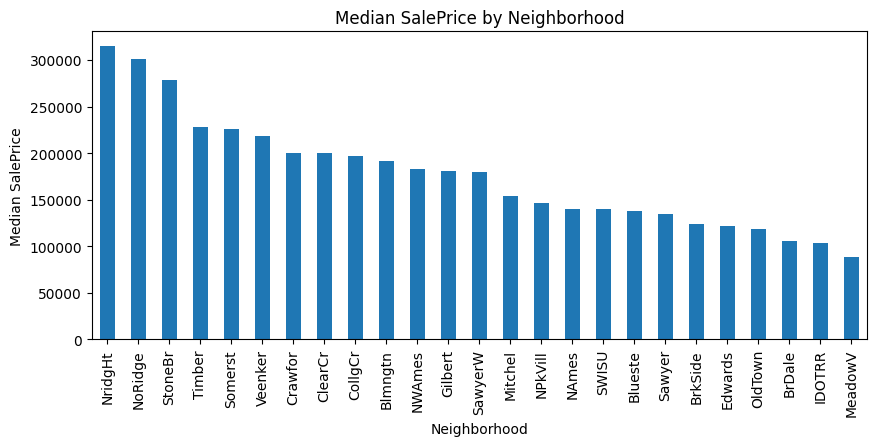

ExterQual       282356.5
Neighborhood    227000.0
BsmtQual        206000.0
KitchenQual     201750.0
CentralAir       70000.0
dtype: float64

In [9]:
#categorical analysis
#For categorical variables, correlation is meaningless, so we do group-by analysis
#for example for a neighborhood doing group by median to find ourt if we know just this one categorz how would the price change
df.groupby("Neighborhood")["SalePrice"].median().sort_values(ascending=False)

plt.figure(figsize=(10,4))
(
    df.groupby("Neighborhood")["SalePrice"]
      .median()
      .sort_values(ascending=False)
      .plot(kind="bar")
)
plt.ylabel("Median SalePrice")
plt.title("Median SalePrice by Neighborhood")
plt.show()
#create large separation in price and some neighbourhoodsy more expensive  
#but we also can look at spread-based importance (how much does the category separate prices)

categorical_cols = [
    "Neighborhood",
    "KitchenQual",
    "ExterQual",
    "BsmtQual",
    "CentralAir"
]

cat_importance = {}

for col in categorical_cols:
    medians = df.groupby(col)["SalePrice"].median()
    cat_importance[col] = medians.max() - medians.min()

pd.Series(cat_importance).sort_values(ascending=False)
#larger ranhe - stronger effect

<Figure size 640x480 with 0 Axes>

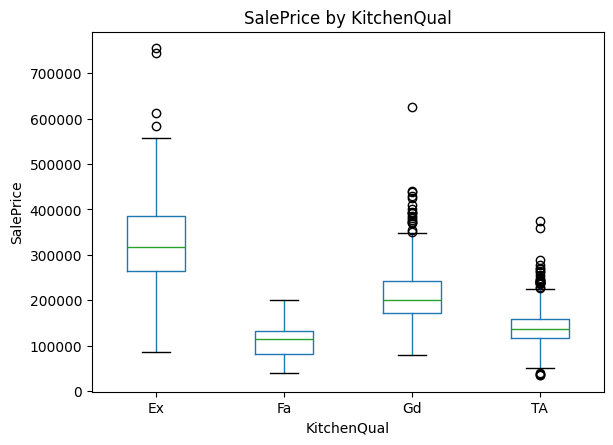

ExterQual       0.556605
KitchenQual     0.408206
BsmtQual        0.402715
Neighborhood    0.300073
CentralAir      0.214724
dtype: float64

In [10]:
#and also we can compare using boxplots looking at the distribution of level
plt.figure()
df.boxplot(column="SalePrice", by="KitchenQual", grid=False)
plt.title("SalePrice by KitchenQual")
plt.suptitle("")
plt.xlabel("KitchenQual")
plt.ylabel("SalePrice")
plt.show()
#can see clear ordering

#also can do normal group effect - 
#Values is here “average relative price shift due to this category”
#so we compare categorical features on the same scale and see which variable matters more overall
global_median = df["SalePrice"].median()

relative_effect = {}
for col in categorical_cols:
    medians = df.groupby(col)["SalePrice"].median()
    relative_effect[col] = ((medians - global_median) / global_median).abs().mean()

pd.Series(relative_effect).sort_values(ascending=False)
#For categorical features, importance is assessed by how strongly the target distribution 
#changes across groups, not by correlation.

In [11]:
#Now we can combine all our chosen columns and target so we are left just with "clean" dataset
#we have some strong numerical predictors like size, quality/condition, capacity, age/remodeling, and categorical like quality, location, amenities
TARGET = "SalePrice"
BASE_FEATURES = [
    "OverallQual", # overall material
    "GrLivArea",
    "TotalBsmtSF",
    "1stFlrSF",
    "GarageCars",
    "GarageArea",
    "YearBuilt",
    "YearRemodAdd",
    "FullBath",
    "TotRmsAbvGrd",
    "Neighborhood",
    "KitchenQual",
    "ExterQual",
    "BsmtQual",
    "CentralAir",
]

# Keep only relevant columns + target
data = df[BASE_FEATURES + [TARGET]].copy()

print("Shape (rows, cols):", data.shape)

Shape (rows, cols): (1460, 16)



Numeric columns: ['OverallQual', 'GrLivArea', 'TotalBsmtSF', '1stFlrSF', 'GarageCars', 'GarageArea', 'YearBuilt', 'YearRemodAdd', 'FullBath', 'TotRmsAbvGrd']

Categorical columns: ['Neighborhood', 'KitchenQual', 'ExterQual', 'BsmtQual', 'CentralAir']

Descriptive statistics (numeric features):
               count         mean         std     min      25%     50%  \
OverallQual   1460.0     6.099315    1.382997     1.0     5.00     6.0   
GrLivArea     1460.0  1515.463699  525.480383   334.0  1129.50  1464.0   
TotalBsmtSF   1460.0  1057.429452  438.705324     0.0   795.75   991.5   
1stFlrSF      1460.0  1162.626712  386.587738   334.0   882.00  1087.0   
GarageCars    1460.0     1.767123    0.747315     0.0     1.00     2.0   
GarageArea    1460.0   472.980137  213.804841     0.0   334.50   480.0   
YearBuilt     1460.0  1971.267808   30.202904  1872.0  1954.00  1973.0   
YearRemodAdd  1460.0  1984.865753   20.645407  1950.0  1967.00  1994.0   
FullBath      1460.0     1.565068    0

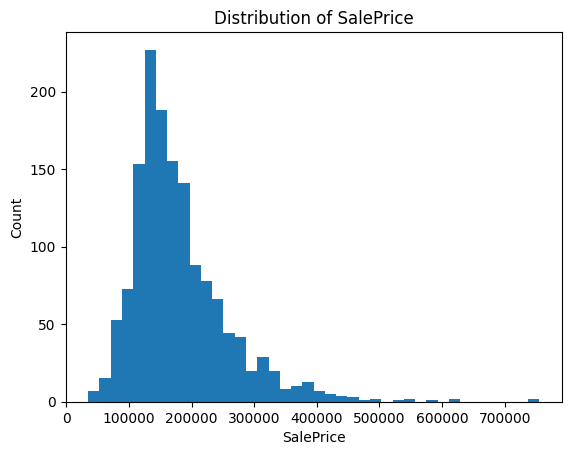

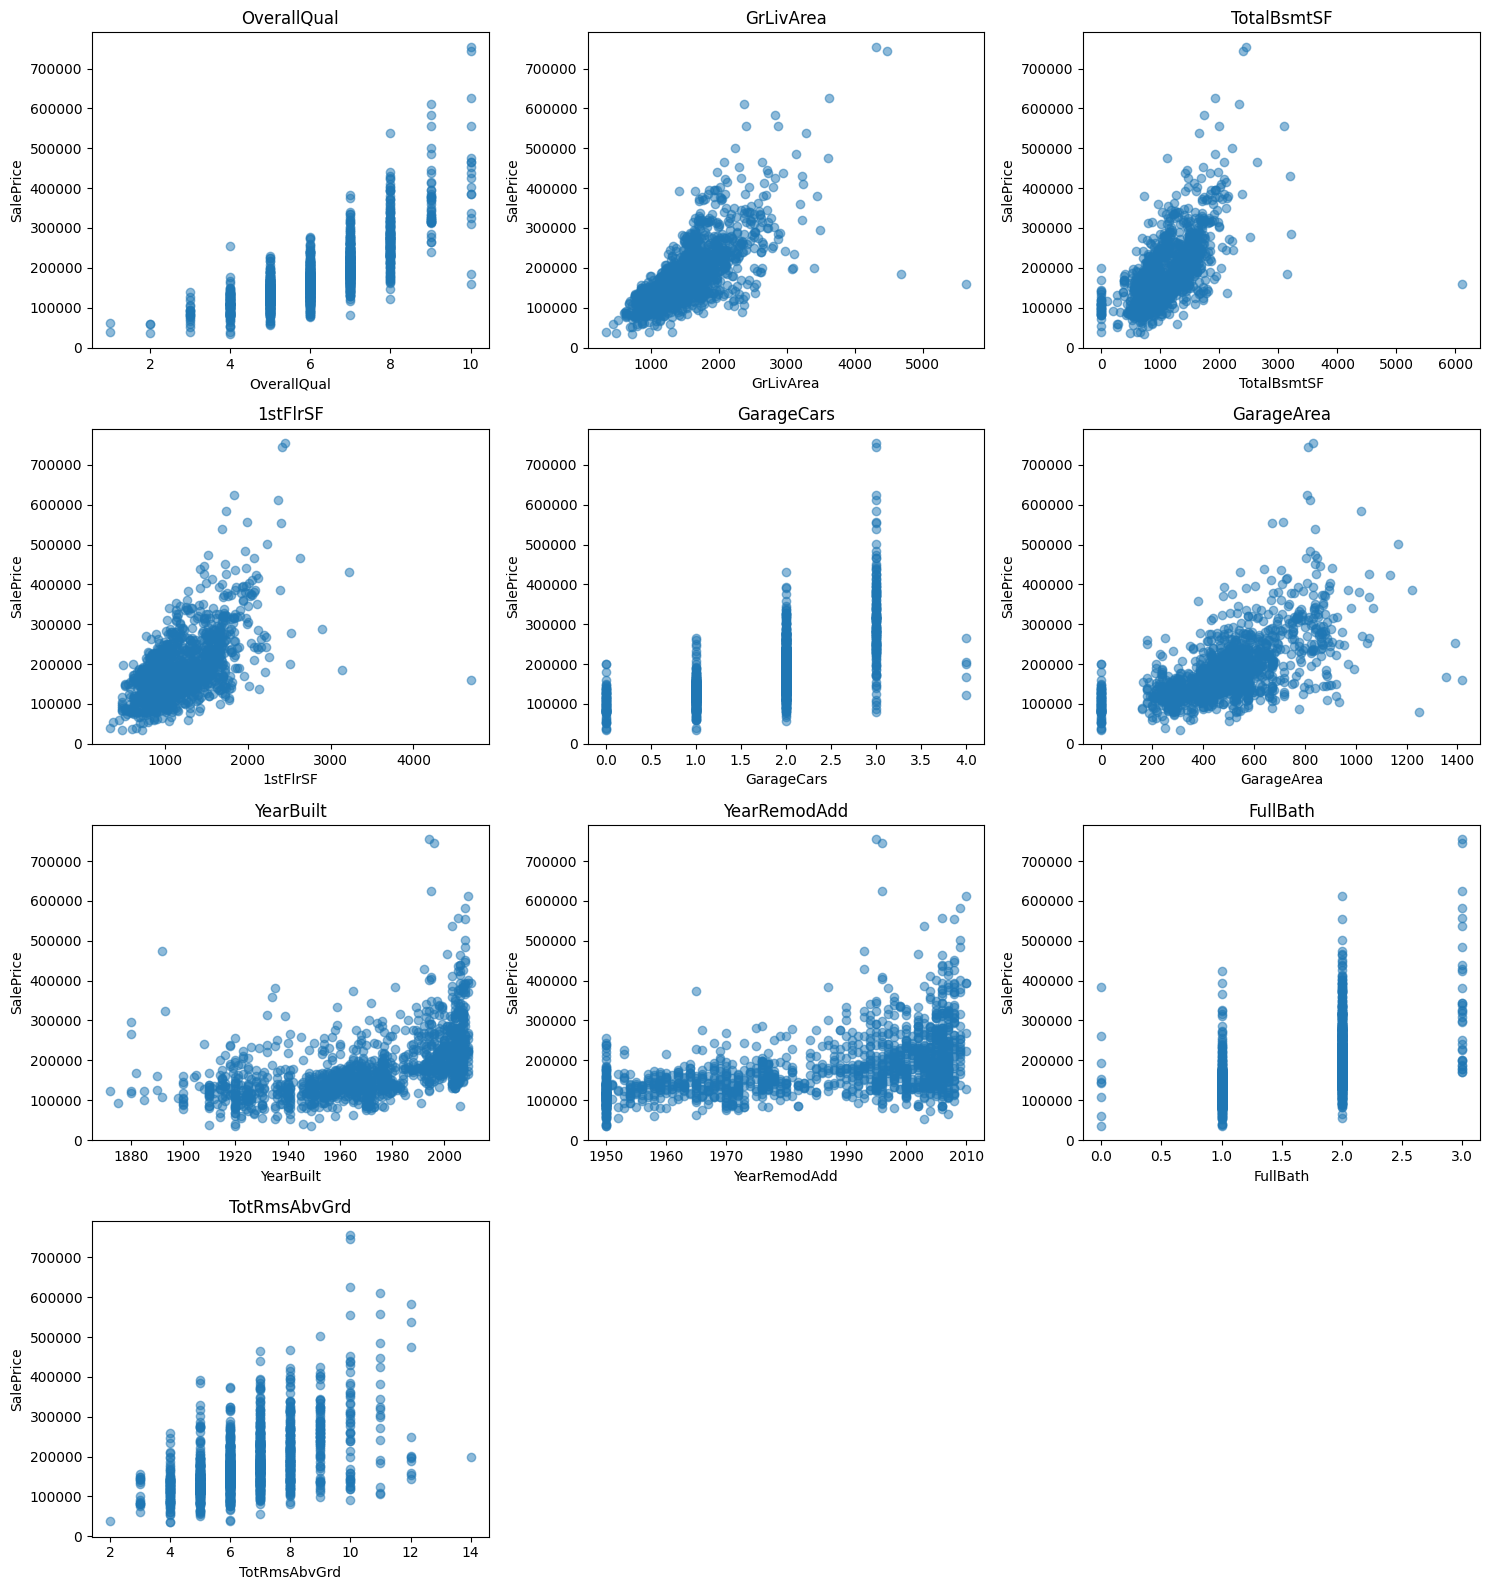

<Figure size 640x480 with 0 Axes>

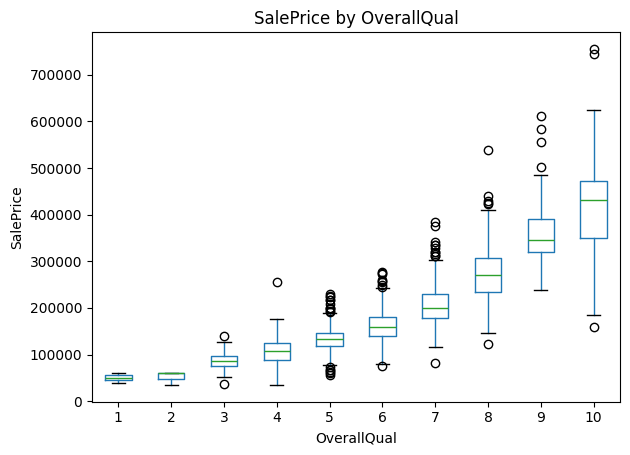

<Figure size 640x480 with 0 Axes>

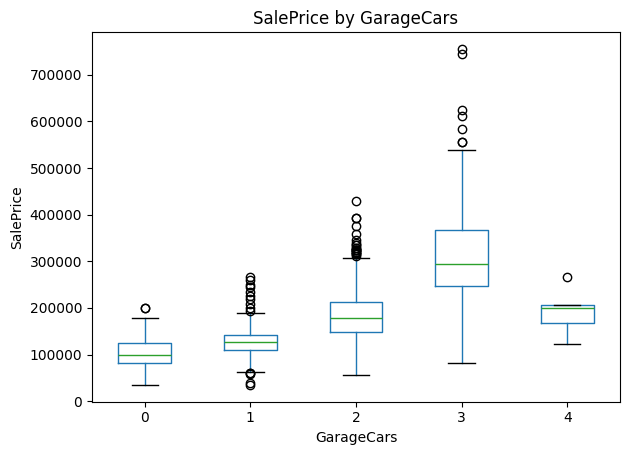

<Figure size 640x480 with 0 Axes>

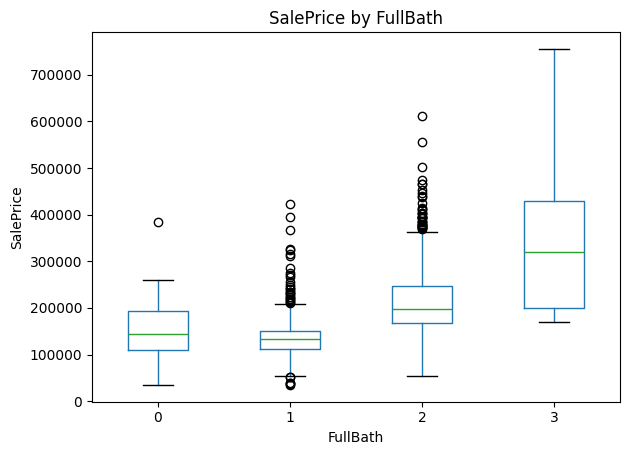

<Figure size 640x480 with 0 Axes>

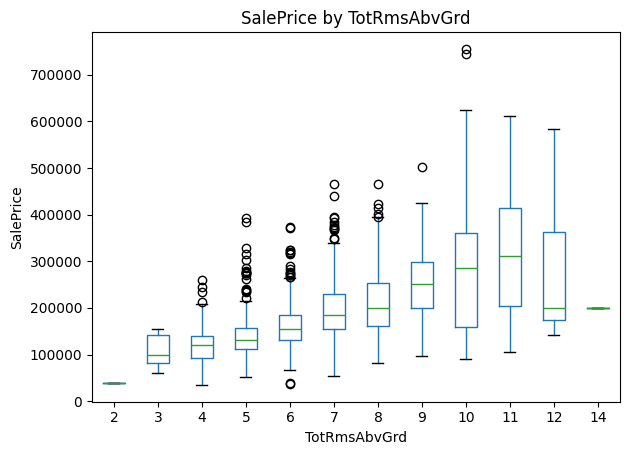

In [12]:
# 1) EDA (on selected 15 columns)

# Missing values overview
missing_table = pd.DataFrame({
    "MissingCount": data.isna().sum(),
    "MissingPercent": data.isna().mean() * 100,
    "Dtype": data.dtypes
})

missing_table = missing_table[missing_table["MissingCount"] > 0] \
                    .sort_values("MissingPercent", ascending=False)
missing_table

# stats for numeric columns
numeric_cols = data[BASE_FEATURES].select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = [c for c in BASE_FEATURES if c not in numeric_cols]

print("\nNumeric columns:", numeric_cols)
print("\nCategorical columns:", categorical_cols)

print("\nDescriptive statistics (numeric features):")
print(data[numeric_cols].describe().T)

# Visualize target distribution (SalePrice is right-skewed, already checked before)
plt.figure()
plt.hist(data[TARGET], bins=40)
plt.title("Distribution of SalePrice")
plt.xlabel("SalePrice")
plt.ylabel("Count")
plt.show()

#Saleprice vs all numerical predictors
n_cols = 3
n_rows = int(np.ceil(len(numeric_cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    axes[i].scatter(data[col], data[TARGET], alpha=0.5)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("SalePrice")
    axes[i].set_title(f"{col}")

# Remove empty subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

#for some numerical columns that are actually counts boxplots are a little bit better to use
#e.g. OverallQual, GarageCars, FullBath - we can or put them manually or just separate by low number (cardinality)

low_cardinality_numeric = [
    col for col in numeric_cols if data[col].nunique() <= 15 #we have 14 max for TotRmsAbvGrd
]

for col in low_cardinality_numeric:
    plt.figure()
    data.boxplot(column=TARGET, by=col, grid=False)
    plt.title(f"SalePrice by {col}")
    plt.suptitle("")
    plt.xlabel(col)
    plt.ylabel("SalePrice")
    plt.tight_layout()
    plt.show()


Box plots are much cleaner than scatter plots for discrete values and they show median shifts, spreads and outliers


Median SalePrice by Neighborhood:
Neighborhood
NridgHt    315000.0
NoRidge    301500.0
StoneBr    278000.0
Timber     228475.0
Somerst    225500.0
Veenker    218000.0
Crawfor    200624.0
ClearCr    200250.0
CollgCr    197200.0
Blmngtn    191000.0
NWAmes     182900.0
Gilbert    181000.0
SawyerW    179900.0
Mitchel    153500.0
NPkVill    146000.0
NAmes      140000.0
SWISU      139500.0
Blueste    137500.0
Sawyer     135000.0
BrkSide    124300.0
Edwards    121750.0
OldTown    119000.0
BrDale     106000.0
IDOTRR     103000.0
MeadowV     88000.0
Name: SalePrice, dtype: float64

Median SalePrice by KitchenQual:
KitchenQual
Ex    316750.0
Gd    201400.0
TA    137000.0
Fa    115000.0
Name: SalePrice, dtype: float64

Median SalePrice by ExterQual:
ExterQual
Ex    364606.5
Gd    220000.0
TA    139450.0
Fa     82250.0
Name: SalePrice, dtype: float64

Median SalePrice by BsmtQual:
BsmtQual
Ex    318000.0
Gd    192070.0
TA    135500.0
Fa    112000.0
Name: SalePrice, dtype: float64

Median SalePric

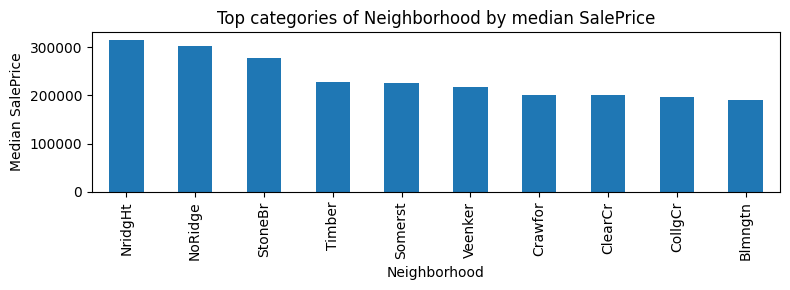

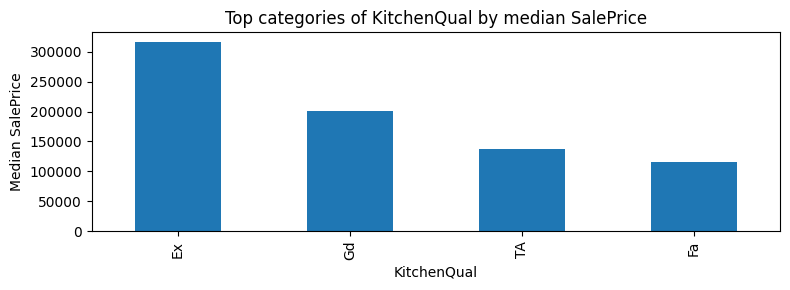

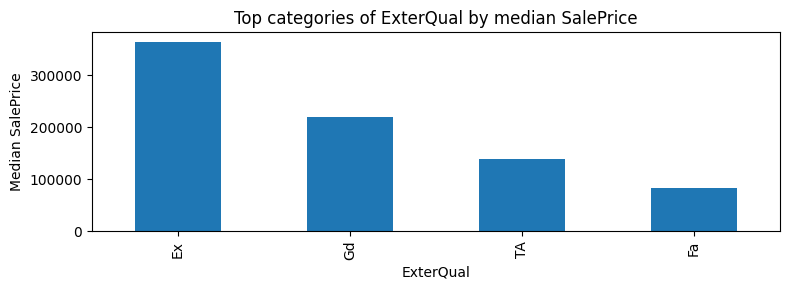

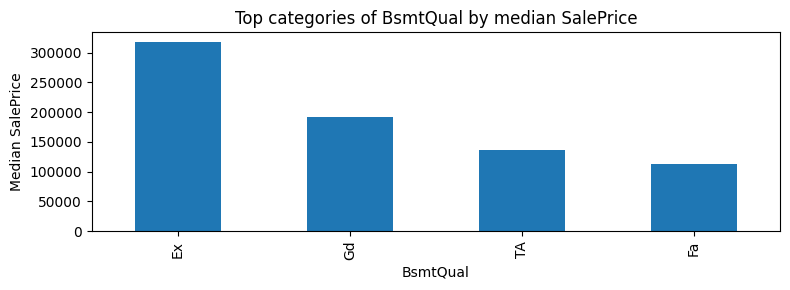

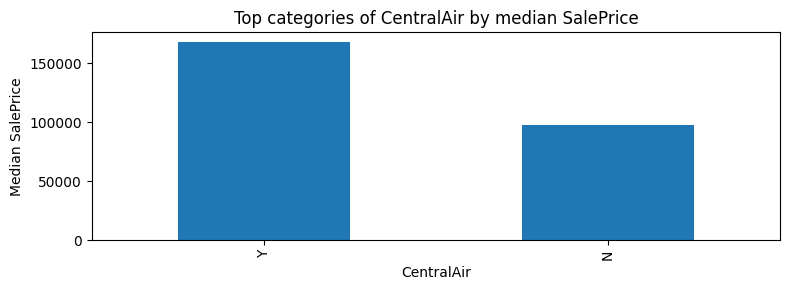

In [13]:
#numerical evidence for every categorical feature
for col in categorical_cols:
    print(f"\nMedian SalePrice by {col}:")
    print(
        data.groupby(col)[TARGET]
            .median()
            .sort_values(ascending=False)
    )
    
for col in categorical_cols:
    medians = (
        data.groupby(col)[TARGET]
            .median()
            .sort_values(ascending=False)
    )

    plt.figure(figsize=(8,3))
    medians.head(10).plot(kind="bar")
    plt.title(f"Top categories of {col} by median SalePrice")
    plt.ylabel("Median SalePrice")
    plt.tight_layout()
    plt.show()


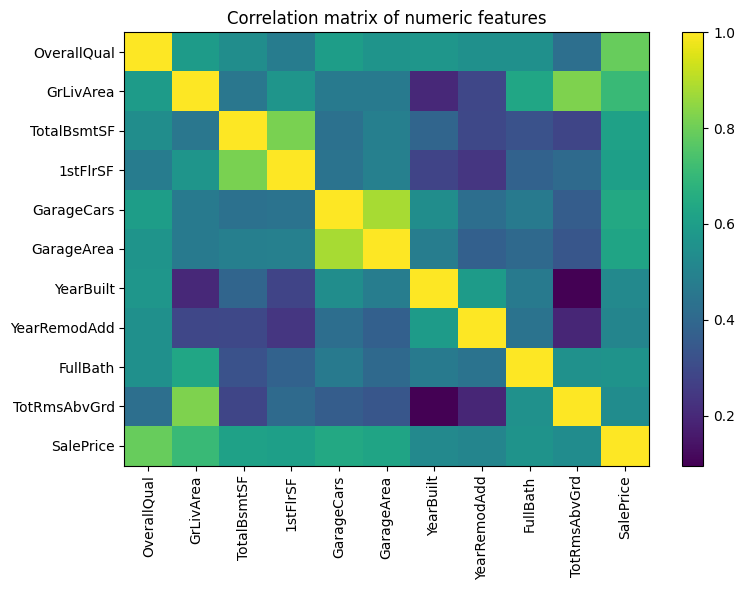

In [14]:
#Correlation heatmap
corr = data[numeric_cols + [TARGET]].corr()

plt.figure(figsize=(8,6))
plt.imshow(corr, aspect="auto")
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation matrix of numeric features")
plt.tight_layout()
plt.show()


FULL EDA ANALYSIS:
Target variable - SalePrice - strong right-skewed distribution, with the majority of houses priced between approximately 100,000 and 250,000, and a small number of very expensive outliers exceeding 500,000. This skewness suggests that extreme values are present and that prediction errors in absolute terms may be disproportionately influenced by high-priced houses. As a result, metrics such as RMSE and RMSLE are appropriate for evaluating model performance, as they capture both absolute and relative prediction errors.

Numerical features: we have clear patterns for all of the chosen features:
OverallQual shows the strongest association with SalePrice (higher quality ratings correspond to substantially higher sale prices) ; GrLivArea (above-ground living area) also have strong positive correlation with SalePrice (larger houses tend to have higher prices, some outliers are visible though); TotalBsmtSF and 1stFlrSF also show clear positive relationships with SalePrice, confirming that both basement and ground-floor space contribute meaningfully to house value (relationship is noisier due to houses with 0 values for these parameters; GarageCars and GarageArea are discrete and also have a correlation with
target - so this is confirming the necessity to take the garage into account; FullBath and TotRmsAbvGrd have similar situation - its showing us that house comfort and complexity have also an impact, but these features are less informative than size features or quality
YearBuilt and YearRemodAdd show moderate positive correlations with SalePrice - newwer houses and more recentlty remodeled are more expensive usually but the relation is not linear, showing that we can have interaction with other variables

Based on correlation matrix we can see that we have moderate correlations among predictors themselves, such as between GarageCars and GarageArea, and between TotalBsmtSF and 1stFlrSF. This multicollinearity motivates the use of regularized models, which can stabilize coefficient estimates in the presence of correlated features.


Categorical Features
Quality-Related Categorical Features
ExterQual, KitchenQual, and BsmtQual show very strong and consistent ordinal effects. Median SalePrice increases monotonically from Fair (Fa) to Excellent (Ex) categories. For example, houses with excellent exterior or kitchen quality have median prices more than double those with fair quality. These clear separations indicate that quality-related categorical features are among the most informative predictors in the dataset.

Location: Neighborhood
Neighborhood exhibits substantial variation in median SalePrice across categories. High-end neighborhoods such as NridgHt, NoRidge, and StoneBr have median prices above 275,000, while lower-priced neighborhoods such as MeadowV and IDOTRR have median prices below 110,000. This confirms that location is a major determinant of house prices, independent of size or quality.

CentralAir
CentralAir shows a clear and interpretable effect: houses with central air conditioning have a median SalePrice approximately 70,000 higher than houses without it. While the effect size is smaller than for quality or location, it is consistent and meaningful.


The exploratory analysis demonstrates that SalePrice is primarily driven by:
Overall quality and finishing standards
House size (above-ground living area, basement area, garage capacity)
Location (neighborhood)
Age and renovation status
Key amenities such as central air conditioning

In [15]:
# 2) Train/Test split (regular split)

X = data[BASE_FEATURES]
y = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("\nTrain size:", X_train.shape, "Test size:", X_test.shape)

# 3) Preprocessing + Model (baseline)

# Why these preprocessing steps:
# - Numeric: impute missing values with median (robust), then scale (ElasticNet benefits from scaling).
# - Categorical: impute missing with most_frequent, then OneHotEncode to turn categories into numeric columns.

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocess = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_cols),
        ("cat", categorical_transformer, categorical_cols),
    ],
    remainder="drop"
)

# Model choice:
# ElasticNet = linear regression with both L1 and L2 regularization (lasso and ridge combined)
#ElasticNet is linear regression with a penalty added to the loss.
# - L1 helps with feature selection / sparsity
# - L2 stabilizes coefficients with correlated predictors
model = ElasticNet(max_iter=20000, random_state=42)

pipe = Pipeline(steps=[
    ("preprocess", preprocess),
    ("model", model)
])



Train size: (1168, 15) Test size: (292, 15)


In [16]:
# 4) Hyperparameter optimization via GridSearchCV

# ElasticNet objective function:
#
#   minimize_w  (1 / (2*n)) * ||y - X @ w||_2^2
#                + alpha * [ (1 - l1_ratio)/2 * ||w||_2^2
#                            + l1_ratio * ||w||_1 ]
#
# where:
#   alpha     = overall regularization strength
#   l1_ratio  = balance between L1 (lasso) and L2 (ridge)
#   l1_ratio = 0 -> pure Ridge, l1_ratio = 1 -> pure Lasso
#this is the notation of skit-learn, some formulas has different notation but idea is the same
param_grid = {
    "model__alpha": np.logspace(-3, 2, 10),     # from 1e-3 to 1e2
    "model__l1_ratio": np.linspace(0.05, 0.95, 10),
}

#  optimize RMSE in dollars (neg_root_mean_squared_error is sklearn convention).
grid = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, y_train)

print("\nBest CV score (negative RMSE):", grid.best_score_)
print("Best hyperparameters:", grid.best_params_)

# CV results overview (top 10 settings)
cv_results = pd.DataFrame(grid.cv_results_).sort_values("rank_test_score").head(10)
print("\nTop 10 CV configurations:")
print(cv_results[["rank_test_score", "mean_test_score", "std_test_score",
                  "param_model__alpha", "param_model__l1_ratio"]])

best_model = grid.best_estimator_

Fitting 5 folds for each of 100 candidates, totalling 500 fits

Best CV score (negative RMSE): -33659.15510488153
Best hyperparameters: {'model__alpha': np.float64(0.003593813663804626), 'model__l1_ratio': np.float64(0.25)}

Top 10 CV configurations:
    rank_test_score  mean_test_score  std_test_score  param_model__alpha  \
12                1    -33659.155105     6976.967188            0.003594   
11                2    -33659.658033     7006.140773            0.003594   
27                3    -33660.504886     7019.435718            0.012915   
13                4    -33660.567977     6945.137449            0.003594   
39                5    -33660.699901     6943.854923            0.046416   
10                6    -33661.763708     7032.965682            0.003594   
14                7    -33664.281043     6910.284673            0.003594   
28                8    -33664.847522     6906.305743            0.012915   
15                9    -33670.769581     6871.965024            0

Hyperparamenter optimization
We optimize the hyperparameters of an ElasticNet regression model, which combines L1 (Lasso) and L2 (Ridge) regularization. The objective function minimized by the model is

(1 / (2*n)) * ||y - X @ w||_2^2 + alpha * [ (1 - l1_ratio)/2 * ||w||_2^2  + l1_ratio * ||w||_1 ]

where alpha controls the overall strength of regularization and l1_ratio (in scikit-learn) determines the balance between L1 and L2 penalties.

We used GridSearchCV with 5 folds cross-validation - its quite common method to select models hyperparameters - we determine ranges fot params we are interesting in and it evaluates all combinations of values and find the one with best performance

5-folds stands here for how much we splitting out training set
For each hyperparameter configuration the model is trained on four folds, evaluated on the remaining fold, and this process is repeated five times so that each fold is used once for validation. The final performance score is the average validation score across the five folds, providing a robust estimate of generalization performance.
This approach reduces dependence on a single train–validation split and helps prevent overfitting during hyperparameter selection. Also it is very useful when we dont have a lot of data so we want to maximize what we are using for training - for example here we have somwe nonlinearitz and instability for higher priced houses - if we splitting data and use just 75 or 80% for training, we can accidentaly cut a lot data that actually would help to find better predictions

so here out parameters is alpha - overall regularization strength and search space was chosen (10e-3, 10e2) and chosen to explore on a logarithmic scale to cover weak to strong regularization regimes. Usually you want to cover quite big range because if you chose narrow from the beginning you can miss your actual best value - but we also dont want go like 10 orders of magnitude because in real life calculations are very expensive and if we are retraining model couple times or every time we are producing predictions it will because very expensive. So idealy we pretraining model with big range (but not too big) and than narrowing it down for future tunning to have it in correct order of magnitude when we know out best performance.
for l1_ration, which is balance between L1 and L2 penalties - search space is from 0.05 to 0.95 - this avoids unstable extremes while allowing the model to interpolate between mostly Ridge and mostly Lasso behavior.

and optimization objective was root mean squared error (RMSE), implemented using scikit-learn’s neg_root_mean_squared_error scoring convention.

Why RMSE instead of MSE or MAE?

well for MSE we measure in squared units (USD² in this case). Squared dollars are hard to interpret and saying “the error is 1.1 billion USD²” has no intuitive meaning so there is more way to makle an error. This is fixed by RMSE because we are taking sq root out of this.
And also RMSE penalises large errors more strongly than MAE, which is important here for higher prices, where under/over-predicting expensive houses by 100k+ is worse than small errors.
In general MAE is good, it trats all errors linearly but does not penalize large outliers strongly and less sensitive when we have huge dynamic range.
Well and also Kaggle House Prices leaderboard also emphasizes RMSE/RMSLE :)

Interpretation of the results of grid search 

Best CV score (negative RMSE): -33659.16
scoring metric is negative RMSE (this is just how scikit-learn works), so - in front is okay
so actual cross-validated RMSE is 33659
which means that on average, across 5-fold cross-validation, model’s predictions are off by ~33.7k dollar, quite a lot but it is reasonable baseline for a simple regularized model on a quite complex dataset and we should perform further improvements like non linear models for example or NN 

Best hyperparameters - alpha = 0.00359, l1_ratio = 0.25
Meaning - very low alpha - close to 0, but not zero - very weak regularization
That probably indicates tha data strongly supports using most of the features and we need just a little bit of regularization to control variance 
Which confirmed that I selected informative features and noisy level in them is moderate.

If alpha were very large, it would mean the model is overfitting badly.
Here, the model prefers to stay close to ordinary least squares

for ratio : l1_ratio = 0.25 - mostly Ridge, some Lasso (l1_ratio = 0 - pure Ridge (L2) and l1_ratio = 1 - pure Lasso (L1))
so the penalty here is 0.75 of L2 and 0.25 of Lasso
that indicates that most selected features contribute useful information and should be shrunk rather than eliminated

also if we look over top 10 cv we can see that many has similar scores meaning model performance is stable and Hyperparameters are not overly sensitive which is good.

And CV standard deviation is around 7000, meaning that variation across RMSE across all 5 folds is approximately 7000 USD, it shows us moderate variability across different data splits



Test set performance
RMSE : 33,632
MAE  : 20,763
R^2  : 0.853
RMSLE: 0.1659


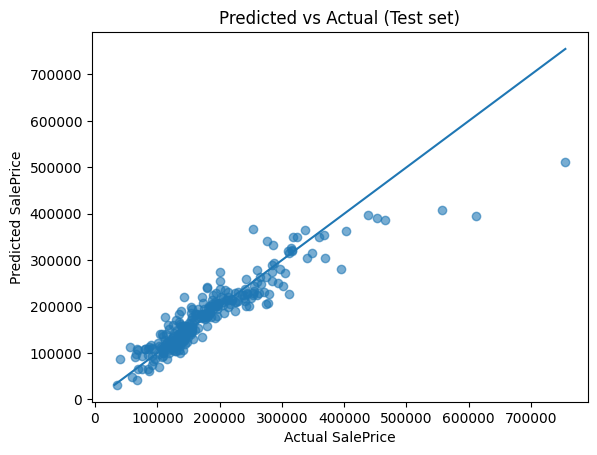

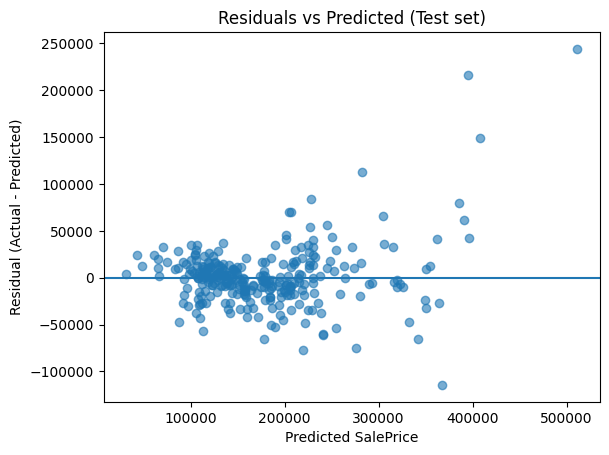

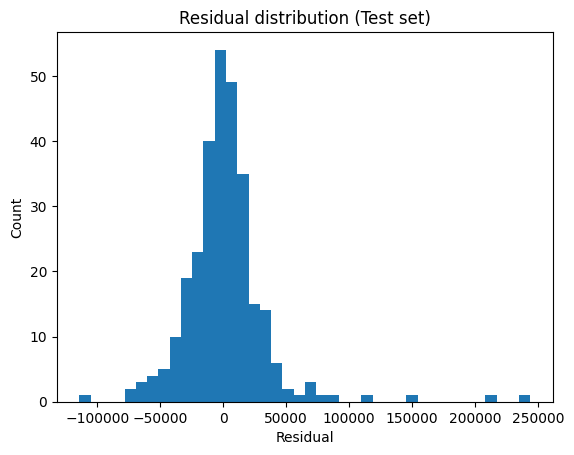

In [17]:
# 5) Evaluate on test set
y_pred = best_model.predict(X_test) #our best model

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# RMSLE is common for this Kaggle problem (uses log scale; requires non-negative predictions)
y_pred_clipped = np.maximum(y_pred, 0)  # avoid negative values for log metric
rmsle = np.sqrt(mean_squared_log_error(y_test, y_pred_clipped))

print("\nTest set performance")
print(f"RMSE : {rmse:,.0f}")
print(f"MAE  : {mae:,.0f}")
print(f"R^2  : {r2:.3f}")
print(f"RMSLE: {rmsle:.4f}")

# 6) Visualize predictions

# Predicted vs Actual (perfect would be a diagonal line)
plt.figure()
plt.scatter(y_test, y_pred, alpha=0.6)
plt.title("Predicted vs Actual (Test set)")
plt.xlabel("Actual SalePrice")
plt.ylabel("Predicted SalePrice")

# Diagonal reference line
min_v = min(y_test.min(), y_pred.min())
max_v = max(y_test.max(), y_pred.max())
plt.plot([min_v, max_v], [min_v, max_v])
plt.show()

# Residual plot (residual = actual - predicted)
residuals = y_test - y_pred
plt.figure()
plt.scatter(y_pred, residuals, alpha=0.6)
plt.title("Residuals vs Predicted (Test set)")
plt.xlabel("Predicted SalePrice")
plt.ylabel("Residual (Actual - Predicted)")
plt.axhline(0)
plt.show()

#Residual distribution
plt.figure()
plt.hist(residuals, bins=40)
plt.title("Residual distribution (Test set)")
plt.xlabel("Residual")
plt.ylabel("Count")
plt.show()

When evaluated on the held-out test set, the model achieves:
RMSE : 33,632
MAE  : 20,763
R^2  : 0.853
RMSLE: 0.1659
rmse is close to train so we have good generalisation. r2 shows that we are explaining around 85% of the variance in house prices, not bad for linear model

the possible explanation why MSE is smaller than RMSE, can be that large errors are relatively rare and that most predictions are close to the true values
rmsle value of 0.166 confirms that relative errors are controlled and that the model does not severely mispredict low-priced houses

so it is possible to say that we have not bad balance model that performs consistently across different price ranges

Visualisation is showing us the next:
for Pred vs true for smaller prices, predictions are clustered around the diagonal which is good, meaning they are close to true values, however we have more deviations from diagonal for very expensive houses and we can see that our model tends to underestimate extreme high price houses - this just confirmed all that was said before about non linear behaviour for extreme properties.


In [20]:
# 7) Feature engineering + re-evaluate
from sklearn.preprocessing import PolynomialFeatures

numeric_cols = data[BASE_FEATURES].select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = [c for c in BASE_FEATURES if c not in numeric_cols]

numeric_transformer_poly = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    #("poly", PolynomialFeatures(degree=2, include_bias=False))
    ("poly", PolynomialFeatures(degree=2, interaction_only=True))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])


preprocessor_poly = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_poly, numeric_cols),
        ("cat", categorical_transformer, categorical_cols),
    ]
)


pipe_poly = Pipeline(steps=[
    ("preprocessor", preprocessor_poly),
    ("model", ElasticNet(max_iter=50000))
])

param_grid_poly = {
    "model__alpha": np.logspace(-2, 2, 10),
    "model__l1_ratio": np.linspace(0.05, 0.6, 8),
}

from sklearn.model_selection import GridSearchCV

grid_poly = GridSearchCV(
    estimator=pipe_poly,
    param_grid=param_grid_poly,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_poly.fit(X_train, y_train)

best_poly_model = grid_poly.best_estimator_

y_pred_poly = best_poly_model.predict(X_test)

rmse_poly = np.sqrt(mean_squared_error(y_test, y_pred_poly))
mae_poly = mean_absolute_error(y_test, y_pred_poly)
r2_poly = r2_score(y_test, y_pred_poly)

y_pred_poly_clipped = np.maximum(y_pred_poly, 0)
rmsle_poly = np.sqrt(mean_squared_log_error(y_test, y_pred_poly_clipped))

print("\nTest set performance (Polynomial degree = 2)")
print(f"RMSE : {rmse_poly:,.0f}")
print(f"MAE  : {mae_poly:,.0f}")
print(f"R^2  : {r2_poly:.3f}")
print(f"RMSLE: {rmsle_poly:.4f}")


print("\n COMPARISON")
print(f"Baseline RMSE   : {rmse:,.0f}")
print(f"Polynomial RMSE : {rmse_poly:,.0f}")
print(f"Baseline RMSLE : {rmsle:.4f}")
print(f"Polynomial RMSLE: {rmsle_poly:.4f}")

Fitting 5 folds for each of 80 candidates, totalling 400 fits

Test set performance (Polynomial degree = 2)
RMSE : 30,431
MAE  : 19,165
R^2  : 0.879
RMSLE: 0.1657

 COMPARISON
Baseline RMSE   : 33,632
Polynomial RMSE : 30,431
Baseline RMSLE : 0.1659
Polynomial RMSLE: 0.1657


Full Poly (deg=2)

Introducing degree-2 polynomial features helped us to improve RMSE / MAE / R2 significantly (for rmse we have almost 7.5% of improvement, which is really good). This indicates that introducing highe pol degree help model to catch non linear behaviour for higher pricing 

hovever, we can see that rmsle is degraded a little but, that probably means that our relative accuracy beco=ame worse in lower pricing range
This shows a trade-off between absolute and relative error minimization when increasing model expressiveness, which is very important to take into account. Further improvements could be done by introducing interaction-only terms, or log-transforming the target variable - this will help with stabilizing of distributions. also possible to allpy polynomial features on a subset of numeric features and not on all of them - because only GrLivArea , TotalBsmtSF, OverallQual have non linear behaviour we are trying to catch with degree 2, so that will propably improve stability overall.

Interaction-only deg =2
difference that interaction only adds just interaction terms and no squares compare to full poly
the squares what was propably the problem before bc they can explode for large values and amplify scale differences and that was probably H
hurting relative accuracy (RMSLE was higher, but not anymore)

Meaning 
House prices are better explained by interactions between features than by strong non-linear curvature in individual features.
The results indicate that interactions between features are more informative than strong non-linear transformations of individual variables, allowing the model to capture complex relationships without distorting relative price scales

### output for PolynomialFeatures(degree=2, include_bias=False))
Fitting 5 folds for each of 80 candidates, totalling 400 fits

Test set performance (Polynomial degree = 2)
RMSE : 31,139
MAE  : 19,503
R^2  : 0.874
RMSLE: 0.1725

 COMPARISON
Baseline RMSE   : 33,632
Polynomial RMSE : 31,139
Baseline RMSLE : 0.1659
Polynomial RMSLE: 0.1725